In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os


In [45]:
data = pd.read_csv("données/LucasBenjamin_664b368abdac8e709d4ff17d.csv", skiprows=1, index_col=3)

## Filtering du dataframe pour 1 sujet

In [3]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered = df_filtered.dropna(subset=["final_angle"])


In [4]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score
0,2305.0,"[186.3297408056, 172.4988425288, 115.6656248854]","[-45.0, -45.0, 45.0]",-24.646771,143.138643,6
1,1958.0,"[98.0630303799, 193.2006295208, 49.6275131924,...","[45.0, -45.0, 45.0, -45.0, 0.0, -45.0, -45.0]",-13.958290,132.662918,0
2,2380.0,"[34.0026636518, 78.5751250026, 144.2219944684,...","[45.0, 45.0, 0.0, 0.0, 0.0]",146.390631,130.568813,6
3,1969.0,"[86.8257191556, 137.819327054, 157.3072000846]","[0.0, -45.0, -45.0]",52.776429,97.281009,0
4,1735.0,"[99.1813592646, 91.1827684021, -22.5187808445,...","[-45.0, -45.0, 45.0, 0.0, 45.0, -45.0, -45.0]",209.237852,31.195139,10
...,...,...,...,...,...,...
195,2426.0,[218.4099821053],[-45.0],-9.130176,173.409982,10
196,2508.0,[195.9147529961],[0.0],15.718573,15.914753,10
197,1822.0,"[159.3437590786, 153.8696178772, 90.66764952, ...","[-45.0, -45.0, 0.0, 0.0, 0.0]",-79.343152,105.643527,10
198,1814.0,[74.993424937],[-45.0],-59.349332,29.993425,0


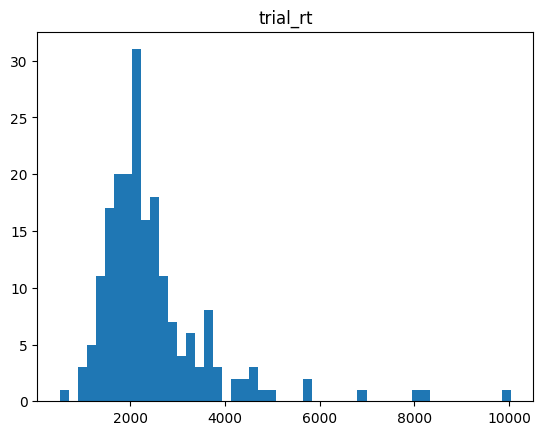

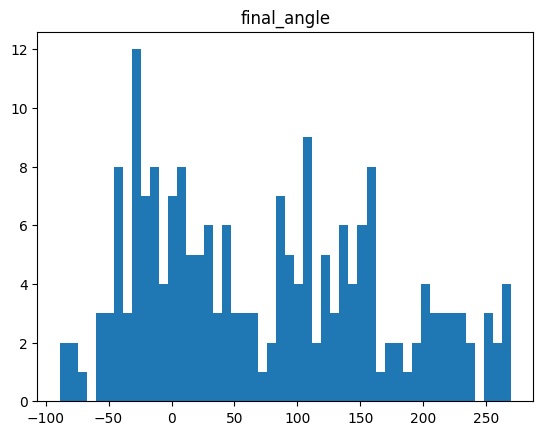

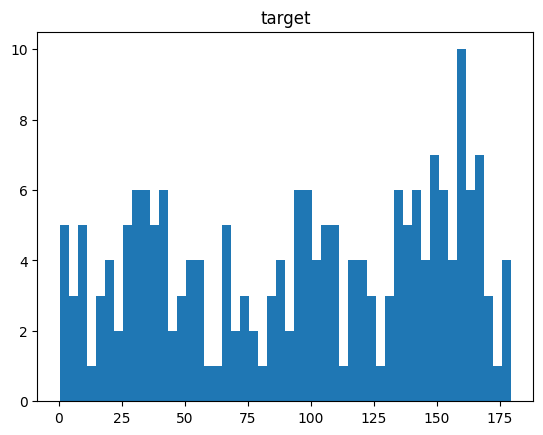

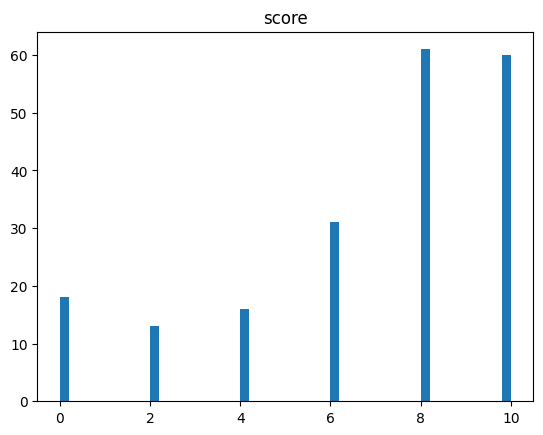

In [5]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## Filtrage des données pour tous

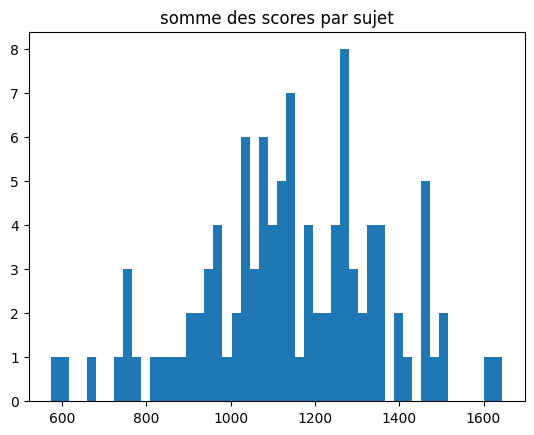

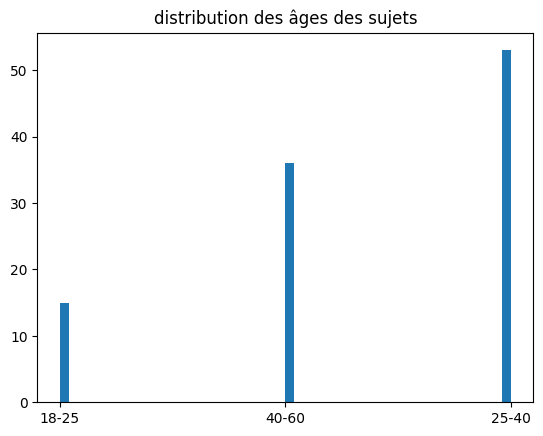

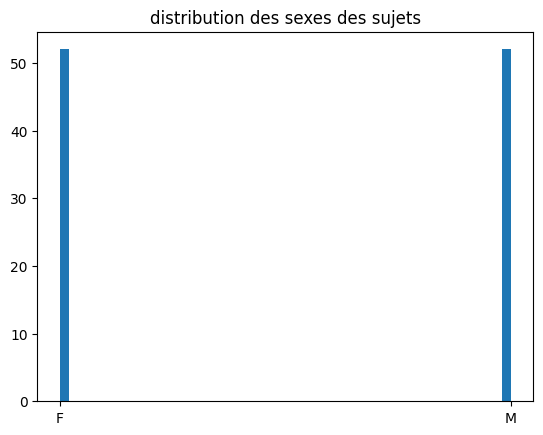

In [54]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for dfs in dfs :     
        age = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][6:11]
        sexe = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][18]
        age_tot = age_tot + [age]
        sexe_tot = sexe_tot + [sexe]
        
        df_filtered = dfs[dfs["stimulus_rotations"].notna()]
        df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
        df_filtered.reset_index(drop=True, inplace=True)
        df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['score'] = df_filtered['score'].astype(int)
        df_filtered = df_filtered.dropna(subset=["final_angle"])
        score_sum.append(df_filtered["score"].sum())
        
    return score_sum, age, age_tot, sexe, sexe_tot


plt.hist(data_sujets(dfs)[0], bins=50)
plt.title("somme des scores par sujet")
plt.show()

plt.hist(data_sujets(dfs)[2], bins=50)
plt.title("distribution des âges des sujets")
plt.show()

plt.hist(data_sujets(dfs)[4], bins=50)
plt.title(f"distribution des sexes des sujets ()")
plt.show()

In [68]:
print("il y a",data_sujets(dfs)[4].count('F'), "femmes")
print("il y a",data_sujets(dfs)[4].count('M'), 'hommes')

il y a 52 femmes
il y a 52 hommes


In [70]:
print("il y a",data_sujets(dfs)[2].count('18-25'), "personnes qui ont entre 18 et 25 ans")
print("il y a",data_sujets(dfs)[2].count('25-40'), 'personnes qui ont entre 25 et 40 ans')
print("il y a",data_sujets(dfs)[2].count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


## dispositoin des angles sur un cercle

In [79]:
def wrap_angle(angle):
    return angle % 360

In [89]:
angle_sujets = wrap_angle(df_filtered['final_angle'].values)

targets = wrap_angle(df_filtered['target'].values)


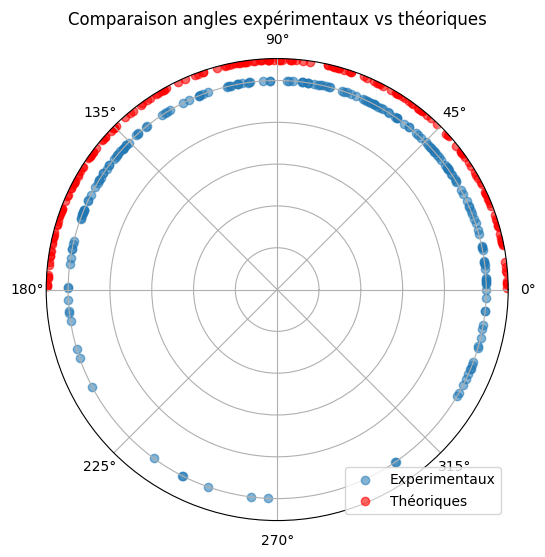

In [93]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

# angles en radians
theta_presented = np.deg2rad(angle_sujets)
theta_targets = np.deg2rad(targets)

# rayon arbitraire (juste pour séparer les couches)
ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])
ax.set_title("Comparaison angles expérimentaux vs théoriques")

ax.legend()
plt.show()


In [83]:
def circular_error(a, b):
    return ((a - b + 180) % 360) - 180

errors = circular_error(
    wrap_angle(df_filtered['final_angle'].values),
    wrap_angle(df_filtered['target'].values)
)


In [84]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score
0,2922.0,"[-3.0912938749, -16.9580510016, 13.4273621149]","[45.0, 45.0, 0.0]",23.164179,27.795279,10
1,2580.0,"[145.3202261314, 142.0681696315, 84.7800554298...","[0.0, 0.0, 45.0, 45.0, 45.0, -45.0, 0.0]",21.134240,160.500241,0
2,4301.0,"[135.4269436659, 69.6084742279, 107.1642506781]","[0.0, 45.0, 0.0]",131.606989,119.021751,6
3,6310.0,"[73.6761902031, 28.7147378745, 54.7920209909]","[45.0, 45.0, 45.0]",78.086976,97.458132,4
4,5313.0,"[35.7995928923, 30.831993453, 10.0712474876, -...","[-45.0, 0.0, 0.0, 45.0, -45.0]",179.268604,15.933681,6
...,...,...,...,...,...,...
195,2652.0,"[202.1896559288, 202.0151805443, 159.4817384062]","[-45.0, -45.0, -45.0]",167.471192,143.200700,2
196,2780.0,"[141.0696971221, 120.8180831235, 150.822708797...","[0.0, 45.0, 45.0, -45.0, 0.0]",148.266481,166.225685,6
197,2820.0,"[119.236972683, 217.2606920663, 199.5020981922]","[45.0, -45.0, -45.0]",-23.912318,163.668882,8
198,2944.0,[216.7223240683],[-45.0],-11.008202,171.722324,10


## implication des rotations dans la détermination des angles

In [94]:
def wrap_angle(angle):
    return angle % 360

start_angle = df_filtered['presented_angles'].apply(lambda x: x[-1])
rotation_sum = df_filtered['stimulus_rotations'].apply(np.sum)
expected_angle = wrap_angle(start_angle + rotation_sum)


In [95]:
def circular_error(a, b):
    return ((a - b + 180) % 360) - 180

df_filtered['rotation_error'] = circular_error(
    wrap_angle(df_filtered['final_angle']),
    expected_angle
)


Erreur = ce que le participant a répondu
− ce qu’il aurait dû répondre s’il appliquait parfaitement la rotation

Gros pic autour de 0°
➡️ Les gens font bien la rotation

Pics autour de ±45°
➡️ Les gens répondent comme s’il n’y avait pas de rotation

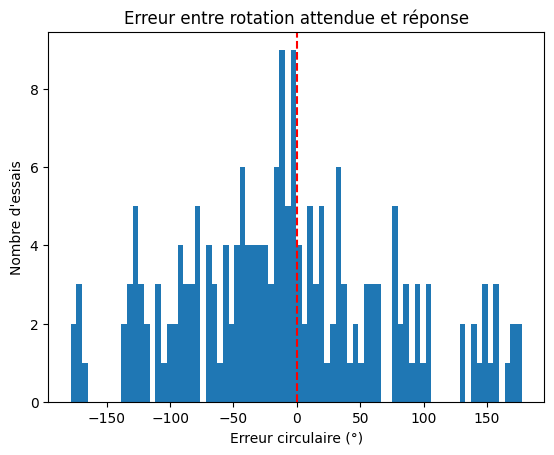

In [105]:
plt.hist(df_filtered['rotation_error'], bins=80)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Erreur circulaire (°)")
plt.ylabel("Nombre d'essais")
plt.title("Erreur entre rotation attendue et réponse")
plt.show()


In [97]:
df_filtered['rotation_type'] = rotation_sum.map({
    -45: '-45',
     0: '0',
     45: '+45'
})


Est-ce que certaines rotations sont plus difficiles que d’autres ?

boîte centrée sur 0 → rotation bien faite

boîte décalée → biais systématique

boîte large → imprécision


0° : bien centré → OK

+45° : décalé vers −20° → sous-rotation

−45° : très dispersé → confus@

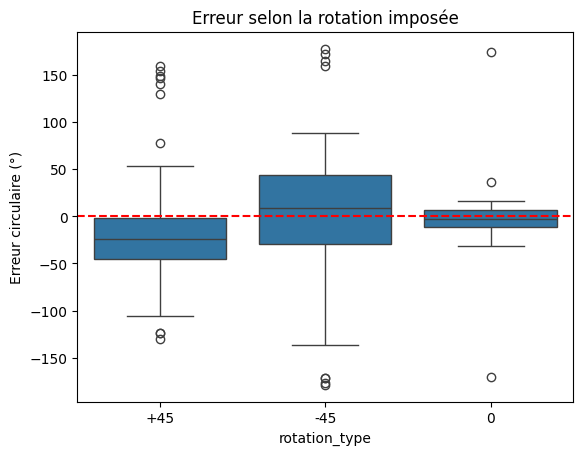

In [98]:
import seaborn as sns

sns.boxplot(
    x='rotation_type',
    y='rotation_error',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.ylabel("Erreur circulaire (°)")
plt.title("Erreur selon la rotation imposée")
plt.show()


Est-ce que rater la rotation fait baisser le score ?

Si + l’erreur augmente, plus le score chute, alors le score reflète la capacité à intégrer la rotation

Si il n'y a pas de relation, alors le score dépend d’autre chose (bruit perceptif, attention…)


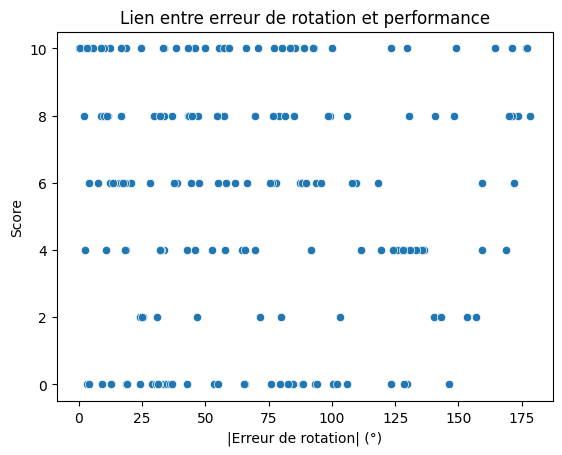

In [99]:
sns.scatterplot(
    x=np.abs(df_filtered['rotation_error']),
    y=df_filtered['score']
)
plt.xlabel("|Erreur de rotation| (°)")
plt.ylabel("Score")
plt.title("Lien entre erreur de rotation et performance")
plt.show()


➡️ Pas de relation
➡️ Le score dépend d’autre chose (bruit perceptif, attention…)

In [100]:
df_filtered[['rotation_error', 'score']].corr()


,rotation_error,score
rotation_error,1.000000,-0.028993
score,-0.028993,1.000000


In [101]:
df_filtered['final_rel_target'] = circular_error(
    df_filtered['final_angle'],
    df_filtered['target']
)


Les gens répondent-ils toujours autour de la target
ou bien la rotation déforme systématiquement leur réponse ?

toutes les boîtes centrées sur 0
→ target bien représentée, rotation intégrée

boîtes décalées selon la rotation
→ la rotation crée un biais cognitif


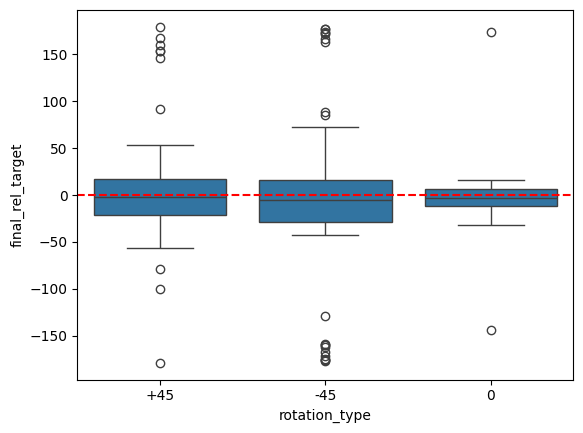

In [102]:
sns.boxplot(
    x='rotation_type',
    y='final_rel_target',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.show()


toutes les boîtes centrées sur 0
→ target bien représentée, rotation intégrée

boîtes décalées selon la rotation
→ la rotation crée un biais cognitif

Ton champ responses contient bien… un dictionnaire stocké dans une cellule pandas 👍
Exemple que tu montres :
{"0": "25-40", "1": "F"}
Voici comment l’“appeler” selon ce que tu veux faire 👇
1️⃣ Accéder au dictionnaire d’une ligne précise
Par exemple à l’index 2 :
data.loc[2, 'responses']
➡️ retourne le dict entier.
2️⃣ Accéder à une valeur du dictionnaire
Toujours pour la ligne 2 :
data.loc[2, 'responses']['0']
➡️ '25-40'
data.loc[2, 'responses']['1']
➡️ 'F'
3️⃣ Si tu filtres d’abord sur trial_type
subset = data[data["trial_type"] == "survey-dropdown"]
Puis par exemple la première ligne :
subset.iloc[0]['responses']['0']
4️⃣ Extraire les valeurs pour TOUTES les lignes
Exemple : récupérer l’âge ("0") pour chaque participant :
data['age'] = data['responses'].apply(lambda x: x.get('0'))
Ou le genre :
data['genre'] = data['responses'].apply(lambda x: x.get('1'))
5️⃣ Vérifier que c’est bien un dict (important)
Parfois c’est une string JSON. Vérifie :
type(data.loc[2, 'responses'])
Si c’est str, alors :
import json
data['responses'] = data['responses'].apply(json.loads)
💡 Résumé rapide
responses = dict dans une cellule
['0'], ['1'] = clés du questionnaire
.apply() = ton meilleur ami pour tout extraire
Si tu veux, dis-moi :
👉 ce que représente "0" et "1"
👉 ou si tu veux transformer tout ça en colonnes propres automatiquement
c'est un string et pas un dictionnaire
Parfait 👍 du coup c’est clair : responses est une string qui contient du JSON.
Il faut donc parser la string → dictionnaire avant d’y accéder.
✅ Solution propre (à faire une seule fois)
import json

data['responses'] = data['responses'].apply(json.loads)
Maintenant :
type(data.loc[2, 'responses'])
➡️ dict
🔍 Accéder aux valeurs ensuite
data.loc[2, 'responses']['0']   # âge
data.loc[2, 'responses']['1']   # genre
📦 Extraire en colonnes séparées (recommandé)
data['age'] = data['responses'].apply(lambda x: x.get('0'))
data['genre'] = data['responses'].apply(lambda x: x.get('1'))
⚠️ Si certaines lignes sont vides / NaN
Version robuste :
def parse_response(x):
    if pd.isna(x):
        return {}
    return json.loads(x)

data['responses'] = data['responses'].apply(parse_response)
🚀 Bonus : éclater toutes les clés automatiquement
Si tu as plein de questions :
responses_df = pd.json_normalize(data['responses'])
data = pd.concat([data, responses_df], axis=1)
Si tu veux, je peux :
mapper les numéros ("0", "1") vers les vraies questions
nettoyer les réponses (catégories, ordres, labels)
t’aider à analyser le questionnaire (stats, plots, etc.)
Dis-moi 👍
je peux pas transformer le string en dictionnaire ,
OK 👍 donc tu n’as pas le droit / la possibilité de modifier la colonne (dataset figé, contraintes du projet, etc.).
Pas de souci — tu peux lire le contenu du string à la volée, sans jamais le transformer dans le DataFrame.
✅ Solution 1 — Accéder à une valeur sans transformer la colonne
import json

json.loads(data.loc[2, 'responses'])['0']
➡️ '25-40'
json.loads(data.loc[2, 'responses'])['1']
➡️ 'F'
👉 Ici, le json.loads() est temporaire, juste pour cette ligne.

✅ Solution 2 — Avec un filtre (trial_type)
subset = data[data["trial_type"] == "survey-dropdown"]

json.loads(subset.iloc[0]['responses'])['0']
✅ Solution 3 — Extraire une valeur sans toucher au DataFrame
Par exemple récupérer l’âge pour toutes les lignes sans modifier responses :
ages = data['responses'].apply(lambda x: json.loads(x)['0'])
👉 responses reste une string, ages est une nouvelle série.
✅ Solution 4 — Version robuste (recommandée)
Si certaines lignes peuvent être vides / mal formées :
import json

def get_value(resp, key):
    try:
        return json.loads(resp).get(key)
    except Exception:
        return None

ages = data['responses'].apply(lambda x: get_value(x, '0'))
genres = data['responses'].apply(lambda x: get_value(x, '1'))
❌ À éviter
eval() → dangereux
Modifier la colonne si tu n’as pas le droit → tu as raison de ne pas le faire
🧠 Résumé
✔ responses reste une string
✔ json.loads() uniquement à l’usage
✔ .apply() pour travailler proprement
✔ aucune mutation du DataFrame
Si tu veux, dis-moi :
si le format est toujours le même
ou si tu veux une fonction générique pour extraire n’importe quelle question automatiquement

euh j'ai fait des hist, mais ya pas une meilleure représentation de ca
😂 oui, ton instinct est bon : un histogramme n’est vraiment pas l’outil adapté ici.
👉 Tes âges sont des catégories, pas une variable continue.
Un hist suppose des valeurs numériques ordonnées… là tu as des tranches d’âge.

✅ Représentation la plus adaptée : bar chart (diagramme en barres)
✔ Simple et lisible
import matplotlib.pyplot as plt

age_counts = ages.value_counts().sort_index()

plt.bar(age_counts.index, age_counts.values)
plt.title("Distribution des âges des sujets")
plt.xlabel("Tranche d'âge")
plt.ylabel("Nombre de participants")
plt.show()
⭐ Encore mieux : barres + pourcentages
Très utile en papier / rapport :
age_pct = ages.value_counts(normalize=True).sort_index() * 100

plt.bar(age_pct.index, age_pct.values)
plt.ylabel("Pourcentage (%)")
plt.title("Répartition des âges des sujets")
plt.show()
🎯 Version clean / publication (conseillée)
order = ["18-25", "25-40", "40-60"]

age_counts = ages.value_counts().reindex(order)

plt.bar(order, age_counts)
plt.title("Répartition des tranches d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Effectif")
plt.tight_layout()
plt.show()
❌ À éviter
histogramme
boxplot
KDE
violin
👉 Ces plots supposent des données numériques continues.
🧠 Règle simple à retenir
Type de variable	Plot adapté
Numérique continu	hist, boxplot
Catégorielle	bar chart
Ordinale	bar chart ordonné
Si tu veux, je peux aussi te proposer :
une version seaborn plus jolie
une version avec annotations (n au-dessus des barres)
ou t’aider à écrire la phrase d’interprétation pour un article / mémoire 📄
je veux positionner des angles sur un cercle trigonométrique, tu peux le faire ? 
Oui, clairement 😄
Et c’est même très propre visuellement pour représenter des angles.
Je te montre comment faire un cercle trigonométrique et placer des angles dessus avec Python / matplotlib.

🧭 Cercle trigonométrique + angles
Exemple : placer quelques angles classiques
import numpy as np
import matplotlib.pyplot as plt

# Angles en radians
angles = [0, np.pi/6, np.pi/4, np.pi/3, np.pi/2]
labels = ["0", "π/6", "π/4", "π/3", "π/2"]

fig, ax = plt.subplots(figsize=(6, 6))

# Cercle unité
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta))

# Axes
ax.axhline(0)
ax.axvline(0)

# Points + segments
for a, lab in zip(angles, labels):
    x, y = np.cos(a), np.sin(a)
    ax.plot([0, x], [0, y])          # rayon
    ax.scatter(x, y)
    ax.text(1.1*x, 1.1*y, lab, ha='center', va='center')

# Mise en forme
ax.set_aspect('equal')
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_title("Cercle trigonométrique")
ax.axis('off')

plt.show()
🔁 Si tu as une liste d’angles en degrés
angles_deg = [30, 45, 60, 90]
angles = np.deg2rad(angles_deg)
Puis même code ensuite.
🎯 Cas courant : visualiser UN angle θ
theta = np.pi / 3

plt.figure(figsize=(5,5))
plt.plot(np.cos(theta), np.sin(theta), 'ro')
plt.plot([0, np.cos(theta)], [0, np.sin(theta)])

circle = plt.Circle((0,0), 1, fill=False)
plt.gca().add_artist(circle)

plt.axhline(0)
plt.axvline(0)
plt.gca().set_aspect('equal')
plt.title("Angle θ = π/3")
plt.axis('off')
plt.show()
🧠

nan pq j'ai ce genre d'angles. et ils peuvent être positionnés n'importe où sur le cercle en mode de n'importe quel cote, donc deux angles peuvent être identiques. je veux que tu fasse une sorte de Gabort tu vois. je veux comparer les angles présentés par les angles théoriques 
Ah ok, je vois très bien 👍
Tu as des angles circulaires, pas des angles “géométriques propres” entre 0 et 360 ordonnés naïvement.
Et tu veux une visualisation type Gabor / espace circulaire pour comparer :
🔵 angles présentés (empiriques)
🔴 angles théoriques / cibles
avec superposition possible (angles identiques autorisés)
sans notion de “bon côté” (tout est modulo 360)
👉 On est clairement dans de la statistique circulaire.
🧠 Principe clé (important)
Un angle :
370° = 10°
-45° = 315°
Donc on doit toujours travailler modulo 360, et visualiser sur un cercle, pas sur un axe.
1️⃣ Normaliser correctement les angles
On met tout dans 
[
0
,
360
[
[0,360[ :
import numpy as np

def wrap_angle(angle):
    return angle % 360
Exemples :
wrap_angle(-45)   # 315
wrap_angle(370)   # 10
2️⃣ Extraire ce que tu veux comparer
Par exemple :
presented_angles = toutes les orientations présentées
target = angle théorique
final_angle = réponse finale
Aplatir les listes d’angles présentés
presented = np.concatenate(df_filtered['presented_angles'].values)
presented = wrap_angle(presented)
Angles théoriques
targets = wrap_angle(df_filtered['target'].values)
3️⃣ Plot circulaire type Gabor / espace d’orientation
Scatter polaire (LA base pour ce que tu veux)
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

# angles en radians
theta_presented = np.deg2rad(presented)
theta_targets = np.deg2rad(targets)

# rayon arbitraire (juste pour séparer les couches)
ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.3, label="Présentés")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])
ax.set_title("Comparaison angles présentés vs théoriques")

ax.legend(loc='upper right')
plt.show()
👉 Résultat :
cercle = espace d’orientation
densité = répétitions possibles
angles identiques se superposent naturellement
4️⃣ Version PLUS Gabor-like (densité circulaire)
Si tu veux un rendu champ de population / tuning :
bins = np.linspace(0, 2*np.pi, 72)
hist, _ = np.histogram(theta_presented, bins=bins, density=True)

fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.plot(bins[:-1], hist, linewidth=2)
ax.fill(bins[:-1], hist, alpha=0.3)

ax.set_yticklabels([])
ax.set_title("Distribution circulaire des angles présentés")
plt.show()
👉 Là tu as un vrai profil d’orientation, comme en vision.
5️⃣ Comparer présenté vs théorique (erreur circulaire)
⚠️ NE JAMAIS faire final - target directement
def circular_error(a, b):
    return ((a - b + 180) % 360) - 180
errors = circular_error(
    wrap_angle(df_filtered['final_angle'].values),
    wrap_angle(df_filtered['target'].values)
)
Puis histogramme circulaire des erreurs 👌
🧠 Résumé conceptuel
Problème	Solution
Angles partout	modulo 360
Deux angles identiques	superposition OK
Pas de “sens”	cercle polaire
Comparaison théorie/donnée	erreur circulaire
Style Gabor	densité circulaire
Si tu veux, au prochain message je peux :
faire un plot présenté / final / target sur le même cercle
faire un tuning curve centrée sur la cible
ou une analyse d’erreur type psychophysique (biais + précision)
Dis-moi ce que tu veux creuser 👀
## dispositoin des angles sur un cercle
def wrap_angle(angle):
    return angle % 360
angle_sujets = wrap_angle(df_filtered['final_angle'].values)

targets = wrap_angle(df_filtered['target'].values)

fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

# angles en radians
theta_presented = np.deg2rad(angle_sujets)
theta_targets = np.deg2rad(targets)

# rayon arbitraire (juste pour séparer les couches)
ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])
ax.set_title("Comparaison angles expérimentaux vs théoriques")

ax.legend()
plt.show()

def circular_error(a, b):
    return ((a - b + 180) % 360) - 180

errors = circular_error(
    wrap_angle(df_filtered['final_angle'].values),
    wrap_angle(df_filtered['target'].values)
)


j'ai ça donc pour un patient, mais est ce que y'a moyen de faire une moyenne pour tous ou jsp 
Oui — et c’est exactement la bonne question 😄
Mais attention ⚠️ : on ne peut PAS faire une moyenne “classique” d’angles.
Il faut une moyenne circulaire, sinon tu obtiens des absurdités (ex : moyenne de 1° et 359° = 180° ❌).
On va faire ça proprement 👇

1️⃣ Moyenne circulaire des angles (tous essais / patients)
Option A — avec scipy (recommandée)
from scipy.stats import circmean, circstd

mean_angle = circmean(
    np.deg2rad(angle_sujets),
    high=2*np.pi,
    low=0
)

std_angle = circstd(
    np.deg2rad(angle_sujets),
    high=2*np.pi,
    low=0
)

mean_angle_deg = np.rad2deg(mean_angle)
std_angle_deg = np.rad2deg(std_angle)

mean_angle_deg, std_angle_deg
👉
mean_angle_deg = orientation moyenne
std_angle_deg = dispersion circulaire
2️⃣ Visualiser la moyenne sur ton cercle
Ajoute juste ce trait :
ax.plot(
    [mean_angle, mean_angle],
    [0, 1.2],
    color='black',
    linewidth=3,
    label='Moyenne circulaire'
)
3️⃣ Moyenne de l’erreur circulaire (le PLUS important scientifiquement)
Souvent on ne moyenne pas les angles bruts, mais l’erreur par rapport à la cible 👌
mean_error = circmean(
    np.deg2rad(errors),
    high=np.pi,
    low=-np.pi
)

std_error = circstd(
    np.deg2rad(errors),
    high=np.pi,
    low=-np.pi
)

np.rad2deg(mean_error), np.rad2deg(std_error)
👉
moyenne ≈ **b
pour chaque angle présenté, les participants doivent tourner soit de 45°, soit de -45°, soit de 0° l'angle qui leur est présenté, selon "stimulus rotation". jsp comment faire, mais j'aimerais regarder si les gens arrivent bien à faire cette rotation ou pas. si ils l'ont prit en compte tu vois. en mode la contribution des rotation +45, -45, et si ça joue sur le score. en mode si le score est bas parce que ils ont pas intégré telle ou telle rotation. on a choisit de leur présenter des angles selon une guassienne, donc la Target est par exemple 27, alors les angles présentés sont choisis selon une gaullienne qui a comme moyenne 27°. donc c'est pas toujours exactement le bon angle c'est ça que je dis 
Ahhh ok — là c’est beaucoup plus clair, et c’est intéressant scientifiquement 👀
Tu veux tester si les participants appliquent correctement les rotations imposées (+45 / −45 / 0), indépendamment du bruit gaussien sur les angles présentés, et voir l’impact sur le score.
On va poser ça proprement, étape par étape.

🧠 Reformulation (important)
Pour chaque essai :
🎯 Target = angle latent (ex. 27°)
🎲 presented_angles = tirés d’une gaussienne centrée sur la target
🔄 stimulus_rotations = suite de rotations imposées (−45, 0, +45)
🧑 final_angle = réponse du participant
⭐ score = performance
👉 Hypothèse clé :
Si le participant intègre correctement les rotations, alors
final_angle ≈ presented_angle + somme(rotations) (modulo 360)
1️⃣ Calculer l’angle théorique attendu
On doit reconstruire, pour chaque essai, ce que le participant aurait dû produire s’il appliquait parfaitement les rotations.
Étape 1 : angle de départ
Tu as plusieurs presented_angles. En général :
soit le dernier présenté
soit la moyenne circulaire
👉 Je prends le dernier angle présenté (dis-moi si ce n’est pas ça).
import numpy as np

def wrap_angle(angle):
    return angle % 360

start_angle = df_filtered['presented_angles'].apply(lambda x: x[-1])
Étape 2 : somme des rotations
rotation_sum = df_filtered['stimulus_rotations'].apply(np.sum)
Étape 3 : angle attendu
expected_angle = wrap_angle(start_angle + rotation_sum)
2️⃣ Erreur circulaire entre attendu et réponse
⚠️ Crucial : erreur circulaire, pas différence naïve.
def circular_error(a, b):
    return ((a - b + 180) % 360) - 180
df_filtered['rotation_error'] = circular_error(
    wrap_angle(df_filtered['final_angle']),
    expected_angle
)
👉 Interprétation :
≈ 0° → rotations bien intégrées
≈ +45° / -45° → rotation oubliée ou inversée
large variance → bruit / stratégie bancale
3️⃣ Est-ce que les participants intègrent les rotations ?
Histogramme des erreurs (diagnostic clé)
plt.hist(df_filtered['rotation_error'], bins=36)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Erreur circulaire (°)")
plt.ylabel("Nombre d'essais")
plt.title("Erreur entre rotation attendue et réponse")
plt.show()
💡 Ce que tu veux voir :
un pic centré sur 0
éventuellement des pics secondaires à ±45 → rotations ignorées
4️⃣ Contribution spécifique de chaque type de rotation
Créer une variable simple :
df_filtered['rotation_type'] = rotation_sum.map({
    -45: '-45',
     0: '0',
     45: '+45'
})
Puis comparer l’erreur :
import seaborn as sns

sns.boxplot(
    x='rotation_type',
    y='rotation_error',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.ylabel("Erreur circulaire (°)")
plt.title("Erreur selon la rotation imposée")
plt.show()
👉 Là tu vois directement :
si +45 est plus dur que −45
si 0° est bien centré
5️⃣ Lien avec le score (TA vraie question)
Est-ce que les erreurs de rotation font baisser le score ?
sns.scatterplot(
    x=np.abs(df_filtered['rotation_error']),
    y=df_filtered['score']
)
plt.xlabel("|Erreur de rotation| (°)")
plt.ylabel("Score")
plt.title("Lien entre erreur de rotation et performance")
plt.show()
Ou corrélation simple :
df_filtered[['rotation_error', 'score']].corr()
👉 Attendu :
plus l’erreur est grande → score plus bas
sinon → le score dépend d’autre chose (bruit perceptif)
6️⃣ BONUS (très clean scientifiquement)
Centrer tout sur la target (retirer la gaussienne)
df_filtered['final_rel_target'] = circular_error(
    df_filtered['final_angle'],
    df_filtered['target']
)
Puis regarder si la rotation explique le biais :
sns.boxplot(
    x='rotation_type',
    y='final_rel_target',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.show()
🧠 Conclusion conceptuelle
Tu peux maintenant répondre à :
✔ Les participants appliquent-ils les rotations ?
✔ Est-ce que +45 ≠ −45 cognitivement ?
✔ Est-ce que les erreurs de rotation expliquent la chute du score ?
✔ Est-ce que le bruit vient de la gaussienne ou de la transformation mentale ?

Si tu veux, au prochain message je peux :

formaliser ça en modèle linéaire / mixte
faire une analyse par sujet
ou t’aider à écrire la méthode + résultats comme dans un papier 🧠📄
"Histogramme des erreurs (diagnostic clé)" je comprends pas ce graphique 

fin en fait j'ai pas compris tes 4 graphiques là 
Très bien — merci de le dire franchement 🙏
On va tout remettre à plat, sans jargon, avec l’intuition cognitive derrière chaque graphique.
Tu n’es pas censé “deviner” ce que ça veut dire : si ce n’est pas clair, c’est que je suis allé trop vite.
🎯 Le cœur de ta question (version simple)
Est-ce que les participants font vraiment la rotation demandée (+45 / −45 / 0)
ou est-ce qu’ils répondent un peu au hasard / oublient la rotation ?
Tous les graphiques servent exactement à répondre à ça, chacun sous un angle différent.
1️⃣ Histogramme des erreurs de rotation
(le plus important, on commence par lui)
Ce qu’on calcule
Pour chaque essai :
Erreur = ce que le participant a répondu
− ce qu’il aurait dû répondre s’il appliquait parfaitement la rotation
erreur ≈ 0° → ✔ rotation bien faite
erreur ≈ +45° ou −45° → ❌ rotation oubliée / mal appliquée
erreur très dispersée → bruit / stratégie instable
Le graphique
plt.hist(rotation_error)
👉 L’axe horizontal = erreur (en degrés)
👉 L’axe vertical = nombre d’essais
Comment le lire (visuellement)
🟢 Cas idéal (participants comprennent la tâche)
      |
      |        ███████
      |     █████████████
      |████████████████████
------|----------------------→ erreur (°)
     -20    0     +20
➡️ Gros pic autour de 0°
➡️ Les gens font bien la rotation
🔴 Cas “ils oublient la rotation”
      |        ███       ███
      |     ███████   ███████
      |███████████████████████
------|------------------------------→
     -45        0        +45
➡️ Pics autour de ±45°
➡️ Les gens répondent comme s’il n’y avait pas de rotation
👉 Ce graphique te dit DIRECTEMENT si la manipulation est intégrée ou pas.
2️⃣ Boxplot par type de rotation
(+45 vs −45 vs 0)
Question posée
Est-ce que certaines rotations sont plus difficiles que d’autres ?
Ce qu’on regarde
Pour chaque condition :
+45°
−45°
0°
on regarde la distribution des erreurs.
Lecture simple
boîte centrée sur 0 → rotation bien faite
boîte décalée → biais systématique
boîte large → imprécision
Exemple interprétation
0° : bien centré → OK
+45° : décalé vers −20° → sous-rotation
−45° : très dispersé → confus
👉 Tu compares directement les stratégies cognitives selon la rotation.
3️⃣ Erreur vs score (scatter plot)
Question posée
Est-ce que rater la rotation fait baisser le score ?
Le graphique
X = |erreur de rotation|
Y = score
Lecture simple
Cas logique
score ↑
       ●
     ●
   ●
 ●
●
----------------→ erreur
➡️ Plus l’erreur augmente, plus le score chute
➡️ Le score reflète la capacité à intégrer la rotation
Cas alternatif
score ↑
●  ●   ●
   ● ●
●   ●
----------------→ erreur
➡️ Pas de relation
➡️ Le score dépend d’autre chose (bruit perceptif, attention…)
4️⃣ Réponse relative à la target (le plus cognitif)
Question posée
Les gens répondent-ils toujours autour de la target
ou bien la rotation déforme systématiquement leur réponse ?
Ce qu’on trace
final_angle − target
par type de rotation.
Lecture simple
toutes les boîtes centrées sur 0
→ target bien représentée, rotation intégrée
boîtes décalées selon la rotation
→ la rotation crée un biais cognitif
🧠 En une phrase par graphique
Graphique	Ce qu’il te dit
Histogramme des erreurs	Est-ce que la rotation est comprise
Boxplot par rotation	Quelle rotation pose problème
Erreur vs score	Est-ce que la rotation impacte la performance
Réponse − target	Comment la rotation biaise la représentation
🛑 Important
Si tu ne devais en garder qu’un seul →
👉 l’histogramme des erreurs de rotation
C’est LE diagnostic.

Si tu veux, au prochain message :
je t’explique un seul graphique avec de FAUSSES données (ultra intuitif)
ou je t’aide à écrire l’interprétation en langage article / mémoire
Dis-moi ce qui te bloque encore exactement 👀






j'ai écrit tout ça dans un autre chat. 